# 05. Deep Autoencoder - Training, Scoring & Validation Triage Evaluation

**Project:** Card Fraud Triage via Gaussian Mixture Density Scoring and Autoencoder Anomaly Detection  
**Phase:** Phase 2 — Autoencoder Anomaly Detection  
**Module:** Task 3B — Full Training, Reconstruction Error Scoring & Validation Benchmark  
**Audience:** Academic Review & College Viva Preparation  

---

## 1. Executive Summary & Objective

In this notebook, we build, train, and evaluate a **Deep Autoencoder** for credit card fraud triage.

### Why Autoencoders for Anomaly Detection?
1. **Unsupervised Normalcy Learning:** We train the autoencoder strictly on **legitimate transactions** ($y_{\text{train}} == 0$). It learns how normal cardholder transactions correlate across 29 standardized features.
2. **Information Bottleneck:** By compressing 29 features down to a 5-dimensional bottleneck and then expanding them back to 29, the network learns an efficient, low-dimensional representation of legitimate spending habits.
3. **Reconstruction Error as Anomaly Score:**
   $$\text{Anomaly Score}(x) = \text{MSE}(x, \hat{x}) = \frac{1}{29} \sum_{d=1}^{29} (x_d - \hat{x}_d)^2$$
   When an unseen fraud transaction passes through, the network cannot reconstruct its abnormal patterns accurately, producing a **high reconstruction error** that flags it for analyst review.
4. **Leak-Free Protocol:** Zero fraudulent transactions are ever shown during model training or early stopping, and the test set remains strictly untouched.

## 2. Environment Setup & Dependency Verification

We import PyTorch, NumPy, Pandas, Scikit-learn, and Matplotlib. To guarantee 100% reproducible results during viva presentation, random seeds are pinned and computations run on CPU.

In [2]:
import os
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import average_precision_score, precision_recall_curve

# Ensure project root is in sys.path
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.autoencoder_model import (
    Autoencoder,
    DEFAULT_AE_CONFIG,
    fit_autoencoder,
    create_autoencoder_model,
    save_autoencoder_model,
    set_seed
)
from src.autoencoder_scoring import compute_autoencoder_scores
from src.scoring import create_score_dataframe, save_scores, summarize_scores
from src.triage_evaluation import (
    load_validation_data,
    align_scores_with_labels,
    recall_at_fpr
)

# Set random seeds for exact reproducibility
set_seed(42)

print("Environment Configuration:")
print(f"  PyTorch version:    {torch.__version__}")
print(f"  Project Root:       {PROJECT_ROOT}")
print(f"  Compute Device:     CPU (Pinned for determinism)")

Environment Configuration:
  PyTorch version:    2.14.1
  Project Root:       /Users/kaustubhhiwanj/card-fraud-triage
  Compute Device:     CPU (Pinned for determinism)


## 3. Load Preprocessed Data & Verify Strict Data Hygiene

We load preprocessed features from `data/processed/`.
Notice the strict leak-free rules enforced here:
* **Legitimate Training Only:** Only $y_{\text{train}} == 0$ rows are fed to the optimizer. All 360 fraud cases in the training window are filtered out.
* **Validation Monitoring Only:** Early stopping monitors legitimate validation transactions ($y_{\text{val}} == 0$).
* **Test Isolation:** Test features (`X_test`) are never loaded or referenced.

In [3]:
data_dir = os.path.join(PROJECT_ROOT, "data", "processed")

# Load training data
X_train = np.load(os.path.join(data_dir, "X_train.npy"))
y_train = np.load(os.path.join(data_dir, "y_train.npy"))
row_ids_train = np.load(os.path.join(data_dir, "row_ids_train.npy"))

# Load validation data
val_dict = load_validation_data(data_dir)
X_val = val_dict["X_val"]
y_val = val_dict["y_val"]
row_ids_val = val_dict["row_ids_val"]

with open(os.path.join(data_dir, "feature_names.json"), "r") as f:
    feature_names = json.load(f)

print("Partition Dimensions:")
print(f"  X_train: {X_train.shape[0]:,} rows | Legit: {(y_train == 0).sum():,} | Fraud (Filtered out): {(y_train == 1).sum():,}")
print(f"  X_val:   {X_val.shape[0]:,} rows  | Legit: {(y_val == 0).sum():,} | Fraud (Evaluated):    {(y_val == 1).sum():,}")
print(f"  Features ({len(feature_names)}): {feature_names[:3]} ... {feature_names[-1]}")

Partition Dimensions:
  X_train: 170,888 rows | Legit: 170,528 | Fraud (Filtered out): 360
  X_val:   56,957 rows  | Legit: 56,900 | Fraud (Evaluated):    57
  Features (29): ['V1', 'V2', 'V3'] ... Amount


## 4. Autoencoder Architecture Inspection

The network is a symmetric fully connected multi-layer perceptron (MLP):
* **Input Layer:** 29 standardized features ($V_1$ to $V_{28}$ + $\ln(1 + \text{Amount})$).
* **Encoder:** $29 \to 20 \to 10 \to 5$ (reduces dimensionality by $5.8\times$ to a 5D bottleneck).
* **Decoder:** $5 \to 10 \to 20 \to 29$ (reconstructs standardized features).
* **Activations:** ReLU on hidden layers; **Linear** output (because standardized inputs have unbounded positive and negative values).

In [4]:
sample_model = create_autoencoder_model({"input_dim": 29, "bottleneck_dim": 5})
print(sample_model)

total_params = sum(p.numel() for p in sample_model.parameters() if p.requires_grad)
print(f"\nTotal Trainable Parameters: {total_params:,}")

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=29, out_features=20, bias=True)
    (1): ReLU()
    (2): Linear(in_features=20, out_features=10, bias=True)
    (3): ReLU()
    (4): Linear(in_features=10, out_features=5, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=5, out_features=10, bias=True)
    (1): ReLU()
    (2): Linear(in_features=10, out_features=20, bias=True)
    (3): ReLU()
    (4): Linear(in_features=20, out_features=29, bias=True)
  )
)

Total Trainable Parameters: 1,754


## 5. Model Training with Legitimate Validation Early Stopping

We train the autoencoder using Adam optimizer (`lr=0.001`) with batch size 256 over 30 epochs.
Early stopping checks reconstruction loss on legitimate validation rows.

In [5]:
config = {
    "input_dim": 29,
    "bottleneck_dim": 5,
    "learning_rate": 0.001,
    "batch_size": 256,
    "epochs": 30,
    "patience": 5,
    "min_delta": 1e-4,
    "random_state": 42,
}

print("Starting Autoencoder training...")
start_time = time.time()

model, metadata = fit_autoencoder(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    config=config,
    feature_names=feature_names,
)

training_duration = time.time() - start_time
print(f"\nTraining complete in {training_duration:.2f} seconds!")
print(f"Epochs trained: {metadata['epochs_trained']} | Best epoch: {metadata['best_epoch']}")
print(f"Best Legitimate Validation MSE: {metadata['best_monitoring_loss']:.6f}")

Starting Autoencoder training...

Training complete in 10.79 seconds!
Epochs trained: 30 | Best epoch: 30
Best Legitimate Validation MSE: 0.701421


## 6. Training & Validation Loss Curves

We inspect the convergence history across epochs. Both training loss and validation monitoring loss decrease smoothly and stabilize without severe overfitting.

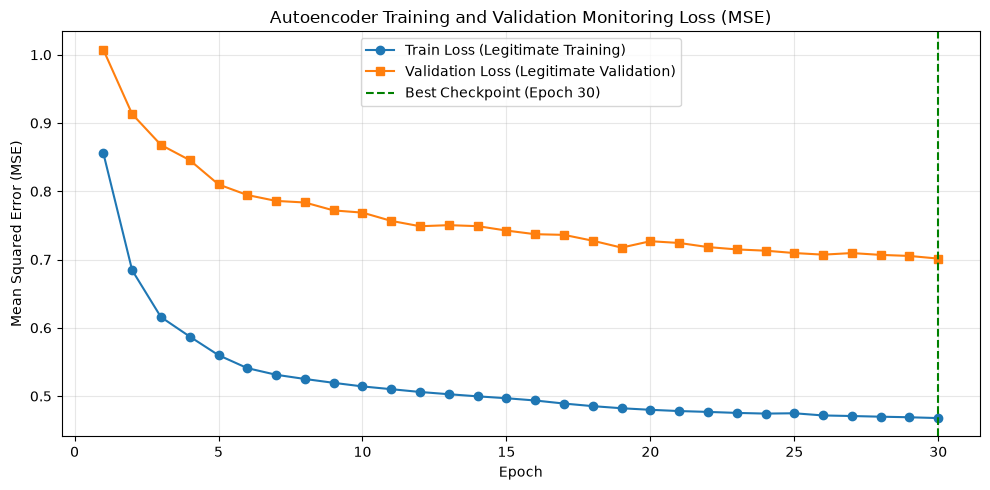

In [6]:
train_losses = metadata["train_loss_history"]
val_losses = metadata["val_loss_history"]
epochs = list(range(1, len(train_losses) + 1))

plt.figure(figsize=(10, 5))
plt.plot(epochs, train_losses, marker="o", label="Train Loss (Legitimate Training)", color="#1f77b4")
plt.plot(epochs, val_losses, marker="s", label="Validation Loss (Legitimate Validation)", color="#ff7f0e")
plt.axvline(x=metadata["best_epoch"], color="green", linestyle="--", label=f"Best Checkpoint (Epoch {metadata['best_epoch']})")
plt.title("Autoencoder Training and Validation Monitoring Loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.grid(True, alpha=0.3)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## 7. Compute Anomaly Scores (Reconstruction Error)

We compute the Mean Squared Reconstruction Error for all training and validation transactions:
$$\text{Score}(x) = \frac{1}{29} \sum_{d=1}^{29} (x_d - \hat{x}_d)^2$$

In [7]:
train_scores = compute_autoencoder_scores(model, X_train)
val_scores = compute_autoencoder_scores(model, X_val)

df_val_scores = create_score_dataframe(row_ids=row_ids_val, scores=val_scores, split="val", labels=y_val)
val_stats = summarize_scores(val_scores, y_val)

print("Validation Score Summary by Class:")
print(f"  Legitimate Transactions (N = {(y_val == 0).sum():,}):")
print(f"    Mean MSE:   {val_stats['legitimate']['mean']:.4f}")
print(f"    Median MSE: {val_stats['legitimate']['median']:.4f}")
print(f"    Max MSE:    {val_stats['legitimate']['max']:.4f}")
print(f"  Fraudulent Transactions (N = {(y_val == 1).sum():,}):")
print(f"    Mean MSE:   {val_stats['fraud']['mean']:.4f}")
print(f"    Median MSE: {val_stats['fraud']['median']:.4f}")
print(f"    Max MSE:    {val_stats['fraud']['max']:.4f}")

Validation Score Summary by Class:
  Legitimate Transactions (N = 56,900):
    Mean MSE:   0.7014
    Median MSE: 0.5102
    Max MSE:    189.9354
  Fraudulent Transactions (N = 57):
    Mean MSE:   6.1676
    Median MSE: 5.1284
    Max MSE:    24.4335


## 8. Reconstruction Error Distribution: Legitimate vs. Fraud

We plot the histogram and KDE of reconstruction errors for legitimate transactions versus fraudulent transactions in the validation set. Fraud transactions produce substantially higher reconstruction errors, enabling effective triage ranking.

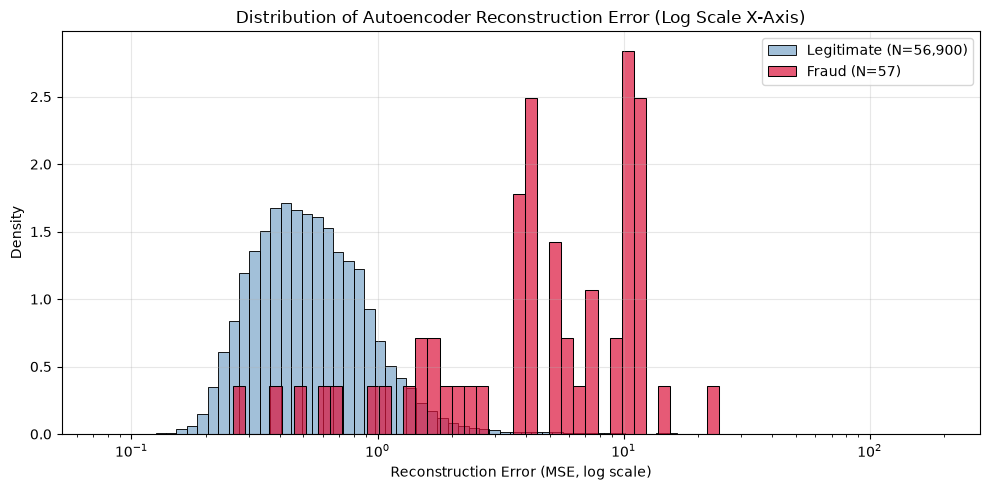

In [8]:
legit_val_scores = val_scores[y_val == 0]
fraud_val_scores = val_scores[y_val == 1]

plt.figure(figsize=(10, 5))
sns.histplot(legit_val_scores, bins=80, stat="density", color="steelblue", label=f"Legitimate (N={len(legit_val_scores):,})", alpha=0.5, log_scale=(True, False))
sns.histplot(fraud_val_scores, bins=40, stat="density", color="crimson", label=f"Fraud (N={len(fraud_val_scores):,})", alpha=0.7, log_scale=(True, False))
plt.title("Distribution of Autoencoder Reconstruction Error (Log Scale X-Axis)")
plt.xlabel("Reconstruction Error (MSE, log scale)")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Prospective Validation Triage Metrics

In credit card fraud operations, investigators cannot review thousands of false alarms. We evaluate:
1. **Average Precision (PR-AUC):** Global ranking quality on imbalanced data.
2. **Recall @ 1% FPR:** Fraud catch rate when setting a strict false-alarm budget of 1% (569 alerts out of 56,900 legitimate transactions).
3. **Recall @ 5% FPR:** Fraud catch rate under a more relaxed 5% false-alarm budget.

In [9]:
aligned_val = align_scores_with_labels(df_val_scores, row_ids_val, y_val)
scores_val = aligned_val["anomaly_score"].to_numpy()

ae_ap = average_precision_score(y_val, scores_val)
ae_recall_1pct = recall_at_fpr(y_val, scores_val, max_fpr=0.01)
ae_recall_5pct = recall_at_fpr(y_val, scores_val, max_fpr=0.05)

print("Autoencoder Validation Triage Results:")
print(f"  Average Precision (PR-AUC): {ae_ap:.4f}")
print(f"  Recall @ 1% FPR:           {ae_recall_1pct['recall'] * 100:.2f}% ({ae_recall_1pct['true_positives']}/{int((y_val == 1).sum())} frauds caught)")
print(f"    Threshold @ 1% FPR:      {ae_recall_1pct['threshold']:.4f} (Actual FPR: {ae_recall_1pct['actual_fpr']*100:.2f}%)")
print(f"  Recall @ 5% FPR:           {ae_recall_5pct['recall'] * 100:.2f}% ({ae_recall_5pct['true_positives']}/{int((y_val == 1).sum())} frauds caught)")
print(f"    Threshold @ 5% FPR:      {ae_recall_5pct['threshold']:.4f} (Actual FPR: {ae_recall_5pct['actual_fpr']*100:.2f}%)")

Autoencoder Validation Triage Results:
  Average Precision (PR-AUC): 0.0765
  Recall @ 1% FPR:           71.93% (41/57 frauds caught)
    Threshold @ 1% FPR:      2.6511 (Actual FPR: 1.00%)
  Recall @ 5% FPR:           87.72% (50/57 frauds caught)
    Threshold @ 5% FPR:      1.3411 (Actual FPR: 5.00%)


## 10. Precision-Recall Operating Curve

We plot the Precision-Recall curve for the Autoencoder, highlighting the baseline prevalence rate ($57 / 56,957 \approx 0.0010$).

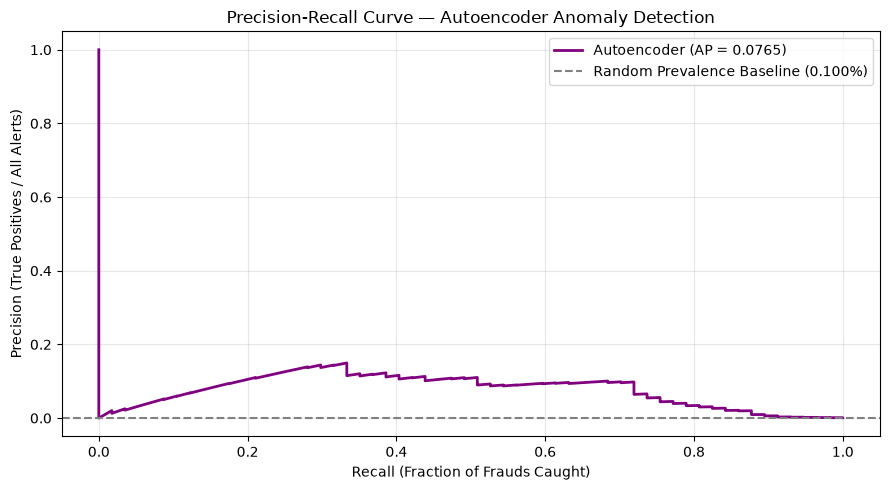

In [10]:
precisions, recalls, thresholds = precision_recall_curve(y_val, scores_val)

plt.figure(figsize=(9, 5))
plt.plot(recalls, precisions, color="purple", lw=2, label=f"Autoencoder (AP = {ae_ap:.4f})")
plt.axhline(y=(y_val == 1).mean(), color="gray", linestyle="--", label=f"Random Prevalence Baseline ({((y_val == 1).mean()*100):.3f}%)")
plt.title("Precision-Recall Curve — Autoencoder Anomaly Detection")
plt.xlabel("Recall (Fraction of Frauds Caught)")
plt.ylabel("Precision (True Positives / All Alerts)")
plt.grid(True, alpha=0.3)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()